In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import json
import warnings

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix, f1_score

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")

In [3]:
CURRENT_DIR = Path.cwd()
PROJECT_ROOT = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR
CONFIG = {
    # Data Paths & Source URLs
    'raw_data_path': PROJECT_ROOT / "data" / "raw" / "adult.data",
    'raw_data_url': "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data",
    'processed_data_path': PROJECT_ROOT / "data" / "processed" / "adult_cleaned.csv",
    
    # Raw Data Schema (UCI raw dataset lacks column headers)
    'raw_column_names': [
        'age', 'workclass', 'fnlwgt', 'education', 'education_num',
        'marital_status', 'occupation', 'relationship', 'race', 'sex',
        'capital_gain', 'capital_loss', 'hours_per_week', 'native_country', 'income'
    ],
    
    # Pandas Loader Settings
    'skipinitialspace': True,
    
    # Model & Pipeline Parameters
    'target_col': 'income',
    'id_cols': [],
    'drop_cols': ['fnlwgt', 'education'],
    'test_size': 0.20,
    'random_state': 42,
    'probability_threshold': 0.40
}

# SCHEMA (race excluded from features, retained in df_processed for auditing)
SCHEMA = {
    'numeric_features': [
        'age', 
        'education_num', 
        'capital_gain_log', 
        'capital_loss_log', 
        'hours_per_week'
    ],
    'categorical_features': [
        'workclass', 
        'marital_status', 
        'occupation', 
        'relationship', 
        'sex', 
        'native_country'
    ]
}

MODEL_PARAMS = {
    'n_estimators': 150,
    'max_depth': 12,
    'min_samples_split': 5,
    'min_samples_leaf': 2,
    'random_state': CONFIG['random_state'],
    'n_jobs': -1
}

In [4]:
def load_raw_data(config: dict) -> pd.DataFrame:
    """
    Loads the raw dataset using configurations defined in the CONFIG dictionary.
    Tries loading from local path first; falls back to streaming from URL if missing.
    """
    local_path = config['raw_data_path']
    
    if local_path.exists():
        print(f"[INFO] Loading raw dataset locally from: {local_path}")
        df = pd.read_csv(
            local_path,
            header=None,
            names=config['raw_column_names'],
            skipinitialspace=config['skipinitialspace']
        )
    else:
        print(f"[WARNING] Local file not found at: {local_path}")
        print(f"[INFO] Streaming raw dataset directly from URL: {config['raw_data_url']}")
        df = pd.read_csv(
            config['raw_data_url'],
            header=None,
            names=config['raw_column_names'],
            skipinitialspace=config['skipinitialspace']
        )
        
    print(f"[SUCCESS] Loaded raw dataset. Shape: {df.shape}")
    return df

In [5]:
def clean_and_engineer_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Cleans raw Adult dataset: fixes '?' NaNs, converts targets,
    and applies Log1p transformation to capital values.
    """
    clean_df = df.copy()
    
    # 1. Clean whitespace from string columns
    for col in clean_df.select_dtypes(include='object').columns:
        clean_df[col] = clean_df[col].str.strip()
        
    # 2. Replace '?' string values with proper np.nan
    clean_df = clean_df.replace('?', np.nan)
    
    # 3. Map Target string labels: '<=50K' -> 0, '>50K' -> 1
    # Handle optional trailing periods in UCI test sets (e.g., '<=50K.')
    clean_df[CONFIG['target_col']] = clean_df[CONFIG['target_col']].str.replace('.', '', regex=False)
    clean_df[CONFIG['target_col']] = clean_df[CONFIG['target_col']].map({'<=50K': 0, '>50K': 1})
    
    # 4. Drop non-predictive/redundant columns
    clean_df = clean_df.drop(columns=[c for c in CONFIG['drop_cols'] if c in clean_df.columns])
    
    # 5. Log-transform skewed capital gain/loss using log1p: log(x + 1)
    clean_df['capital_gain_log'] = np.log1p(clean_df['capital_gain'])
    clean_df['capital_loss_log'] = np.log1p(clean_df['capital_loss'])
    clean_df = clean_df.drop(columns=['capital_gain', 'capital_loss'])
    
    return clean_df

In [6]:
# 1. Load raw dataset via CONFIG
raw_df = load_raw_data(CONFIG)

# 2. Clean and engineer features using your function
df_processed = clean_and_engineer_data(raw_df)

# 3. Quick verification
print("\n--- PROCESSED DATAFRAME PREVIEW ---")
print(f"Processed Shape: {df_processed.shape}")
df_processed.head()

[WARNING] Local file not found at: /home/stephen/projects/ml-production/data/raw/adult.data
[INFO] Streaming raw dataset directly from URL: https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data
[SUCCESS] Loaded raw dataset. Shape: (32561, 15)

--- PROCESSED DATAFRAME PREVIEW ---
Processed Shape: (32561, 13)


,age,workclass,education_num,marital_status,occupation,relationship,race,sex,hours_per_week,native_country,income,capital_gain_log,capital_loss_log
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,40,United-States,0,7.685,0.000
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,13,United-States,0,0.000,0.000
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,40,United-States,0,0.000,0.000
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,40,United-States,0,0.000,0.000
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,40,Cuba,0,0.000,0.000


In [7]:
# ==============================================================================
# DATA QUALITY AUDIT
# ==============================================================================

# 1. Inspect total missing values (converted from '?')
missing_count = df_processed.isna().sum()
missing_percent = (missing_count / len(df_processed)) * 100

audit_df = pd.DataFrame({
    'Missing_Count': missing_count,
    'Missing_Percentage (%)': missing_percent.round(2)
})

# Display only features containing missing values
print("=== 📊 MISSING VALUE AUDIT ===")
print(audit_df[audit_df['Missing_Count'] > 0])

# 2. Check dataset dimensions
print(f"\n=== 📐 SHAPE AUDIT ===")
print(f"Total Samples (Rows): {df_processed.shape[0]:,}")
print(f"Total Features (Cols): {df_processed.shape[1]}")

=== 📊 MISSING VALUE AUDIT ===
                Missing_Count  Missing_Percentage (%)
workclass                1836                   5.640
occupation               1843                   5.660
native_country            583                   1.790

=== 📐 SHAPE AUDIT ===
Total Samples (Rows): 32,561
Total Features (Cols): 13


In [8]:
categorical_transformer = SklearnPipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),  # Mode Imputation
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

In [9]:
# ==============================================================================
# 1. TARGET CLASS DISTRIBUTION
# ==============================================================================
target_counts = df_processed[CONFIG['target_col']].value_counts()
target_props = df_processed[CONFIG['target_col']].value_counts(normalize=True)

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Proportion (%)': (target_props * 100).round(2)
})
target_summary.index = ['<=50K (0)', '>50K (1)']

print("=== ⚖️ TARGET CLASS DISTRIBUTION ===")
print(target_summary)

# ==============================================================================
# 2. TOP FEATURE INTERACTIONS (Bivariate Rate)
# ==============================================================================
print("\n=== 📊 HIGH-INCOME RATE BY MARITAL STATUS ===")
marital_rate = (df_processed.groupby('marital_status')[CONFIG['target_col']].mean() * 100).round(2)
print(marital_rate.sort_values(ascending=False))

print("\n=== 📊 HIGH-INCOME RATE BY EDUCATION NUM ===")
edu_rate = (df_processed.groupby('education_num')[CONFIG['target_col']].mean() * 100).round(2)
print(edu_rate.sort_values(ascending=False))

=== ⚖️ TARGET CLASS DISTRIBUTION ===
           Count  Proportion (%)
<=50K (0)  24720          75.920
>50K (1)    7841          24.080

=== 📊 HIGH-INCOME RATE BY MARITAL STATUS ===
marital_status
Married-civ-spouse      44.680
Married-AF-spouse       43.480
Divorced                10.420
Widowed                  8.560
Married-spouse-absent    8.130
Separated                6.440
Never-married            4.600
Name: income, dtype: float64

=== 📊 HIGH-INCOME RATE BY EDUCATION NUM ===
education_num
16   74.090
15   73.440
14   55.660
13   41.480
11   26.120
12   24.840
10   19.020
9    15.950
8     7.620
6     6.650
4     6.190
5     5.250
7     5.110
3     4.800
2     3.570
1     0.000
Name: income, dtype: float64


In [10]:
# Create an EDA working copy from raw_df
df_eda = raw_df.copy()

# Ensure clean target mapping for EDA calculations
df_eda['target'] = (
    df_eda['income'].str.replace('.', '', regex=False).str.strip() == '>50K'
).astype(int)

# Corrected Country Regional Mapping
def categorize_country(country):
    if pd.isna(country) or country == '?':
        return 'Missing / Unknown'
    elif country == 'United-States':
        return 'United States'
    elif country in ['Canada', 'Germany', 'England', 'France', 'Italy', 'Holand-Netherlands', 'Greece', 'Ireland', 'Hungary', 'Scotland', 'Yugoslavia', 'Poland', 'Portugal']:
        return 'Europe & Developed Markets'
    elif country in ['Mexico', 'Puerto-Rico', 'El-Salvador', 'Dominican-Republic', 'Cuba', 'Jamaica', 'Guatemala', 'Haiti', 'Nicaragua', 'Trinadad&Tobago', 'Honduras', 'Outlying-US(Guam-USVI-etc)', 'Columbia', 'Ecuador', 'Peru']:
        return 'Latin America & Caribbean'
    elif country in ['Philippines', 'India', 'China', 'Taiwan', 'Vietnam', 'Iran', 'South', 'Japan', 'Thailand', 'Hong', 'Cambodia', 'Laos']:
        return 'Asia & Middle East'
    else:
        return 'Other Regions'

df_eda['country_region'] = df_eda['native_country'].apply(categorize_country)

# Run regional summary
region_summary = df_eda.groupby('country_region')['target'].agg(['count', 'mean']).sort_values(by='mean', ascending=False)
region_summary['mean'] = (region_summary['mean'] * 100).round(2).astype(str) + '%'
print(region_summary.rename(columns={'count': 'Total_Count', 'mean': 'High_Income_Rate'}))

                            Total_Count High_Income_Rate
country_region                                          
Europe & Developed Markets          642           29.75%
Asia & Middle East                  751           29.56%
Missing / Unknown                   583           25.04%
United States                     29170           24.58%
Latin America & Caribbean          1415            7.84%


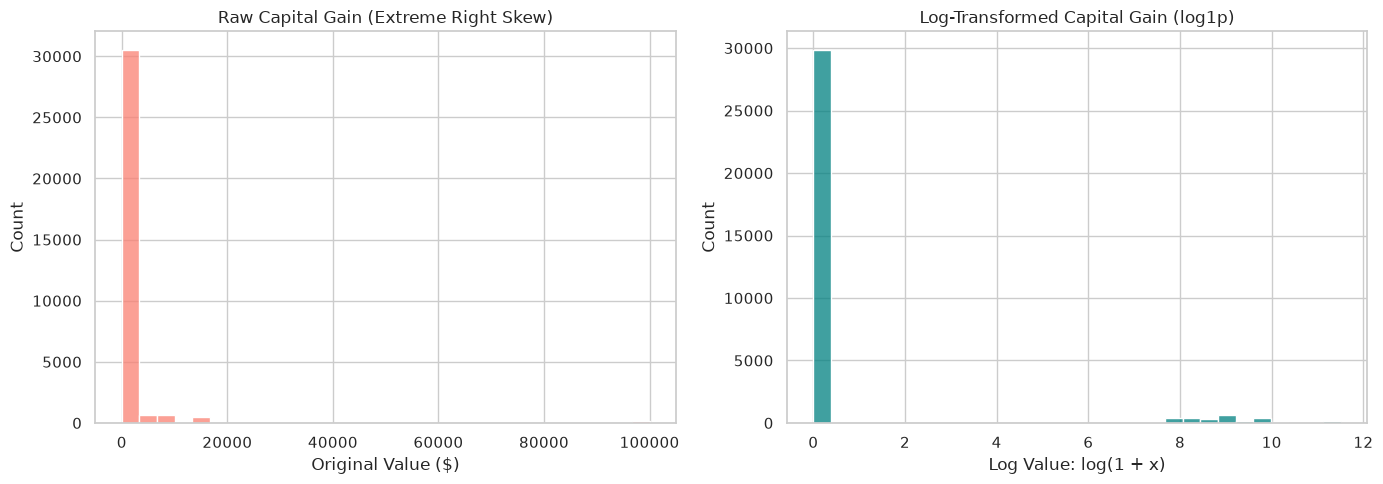

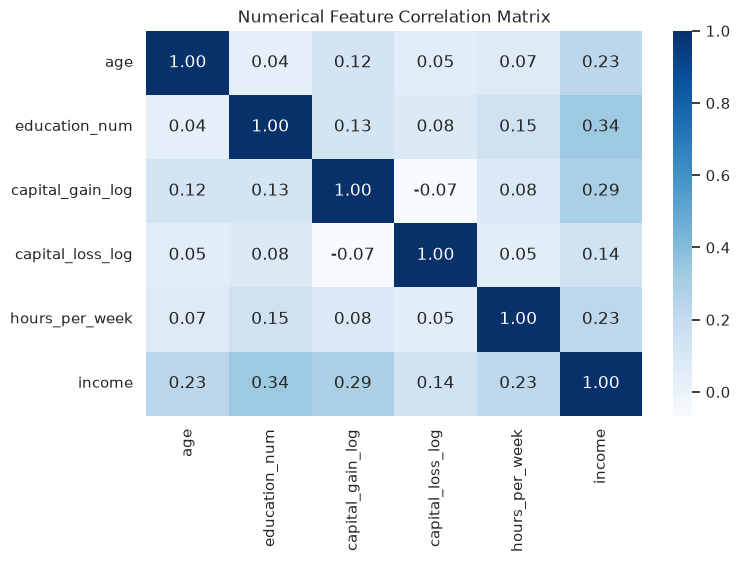

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Before vs. After Log Transformation
sns.histplot(df_eda['capital_gain'], ax=axes[0], color='salmon', bins=30, kde=False)
axes[0].set_title("Raw Capital Gain (Extreme Right Skew)", fontsize=12)
axes[0].set_xlabel("Original Value ($)")

sns.histplot(df_processed['capital_gain_log'], ax=axes[1], color='teal', bins=30, kde=False)
axes[1].set_title("Log-Transformed Capital Gain (log1p)", fontsize=12)
axes[1].set_xlabel("Log Value: log(1 + x)")

plt.tight_layout()
plt.show()

# 2. Numerical Correlation Heatmap
plt.figure(figsize=(8, 5))
num_cols = SCHEMA['numeric_features'] + [CONFIG['target_col']]
sns.heatmap(df_processed[num_cols].corr(), annot=True, fmt=".2f", cmap="Blues")
plt.title("Numerical Feature Correlation Matrix", fontsize=12)
plt.show()

In [12]:

# 1. Separate Features (X) and Target (y)
X = df_processed.drop(columns=[CONFIG['target_col']])
y = df_processed[CONFIG['target_col']]

# 2. Stratified Split (preserves class imbalance ratio in both train and test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=CONFIG['test_size'], 
    random_state=CONFIG['random_state'], 
    stratify=y
)

print(f"✅ Training set shape: {X_train.shape}")
print(f"✅ Test set shape: {X_test.shape}")

✅ Training set shape: (26048, 12)
✅ Test set shape: (6513, 12)


In [13]:
# Numeric pipeline: Impute missing medians -> Robust Scaling
numeric_transformer = SklearnPipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', RobustScaler())
])

# Categorical pipeline: Impute most frequent -> One-Hot Encoding
categorical_transformer = SklearnPipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

# Master preprocessor mapping features by SCHEMA
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, SCHEMA['numeric_features']),
    ('cat', categorical_transformer, SCHEMA['categorical_features'])
])

In [14]:
# Define our comparison suite
experiments = {
    "1_Baseline_Logistic": ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000, random_state=CONFIG['random_state']))
    ]),
    "2_SMOTE_Logistic": ImbPipeline([
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=CONFIG['random_state'])),
        ('classifier', LogisticRegression(max_iter=1000, random_state=CONFIG['random_state']))
    ]),
    "3_Balanced_RandomForest": ImbPipeline([
        ('preprocessor', preprocessor),
        ('classifier', RandomForestClassifier(class_weight='balanced', random_state=CONFIG['random_state'], n_jobs=-1))
    ])
}

# Run training and evaluation
results = []
for name, pipeline in experiments.items():
    print(f"🔄 Training {name}...")
    pipeline.fit(X_train, y_train)
    
    y_pred = pipeline.predict(X_test)
    y_proba = pipeline.predict_proba(X_test)[:, 1]
    
    report = classification_report(y_test, y_pred, output_dict=True)
    
    results.append({
        "Model": name,
        "ROC-AUC": round(roc_auc_score(y_test, y_proba), 4),
        "Class 1 Recall": round(report['1']['recall'], 4),
        "Class 1 Precision": round(report['1']['precision'], 4),
        "Macro F1": round(f1_score(y_test, y_pred, average='macro'), 4)
    })

# Summary Table
benchmark_df = pd.DataFrame(results)
print("\n=== 📊 BENCHMARK RESULTS ===")
print(benchmark_df.to_string(index=False))

🔄 Training 1_Baseline_Logistic...
🔄 Training 2_SMOTE_Logistic...
🔄 Training 3_Balanced_RandomForest...

=== 📊 BENCHMARK RESULTS ===
                  Model  ROC-AUC  Class 1 Recall  Class 1 Precision  Macro F1
    1_Baseline_Logistic    0.900           0.608              0.721     0.781
       2_SMOTE_Logistic    0.899           0.843              0.558     0.765
3_Balanced_RandomForest    0.893           0.754              0.614     0.779


In [15]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1. Define 5-Fold Stratified Cross-Validation Strategy
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=CONFIG['random_state'])

# 2. Metrics to track
scoring_metrics = ['precision', 'recall', 'roc_auc', 'f1_macro']

cv_results_list = []

# 3. Evaluate pipelines across 5 folds
for name, pipeline in experiments.items():
    print(f"🔄 Running 5-Fold CV for {name}...")
    scores = cross_validate(
        pipeline, X, y, 
        cv=cv_strategy, 
        scoring=scoring_metrics, 
        n_jobs=-1
    )
    
    cv_results_list.append({
        "Model": name,
        "CV Precision (Mean ± Std)": f"{np.mean(scores['test_precision']):.3f} ± {np.std(scores['test_precision']):.3f}",
        "CV Recall (Mean ± Std)": f"{np.mean(scores['test_recall']):.3f} ± {np.std(scores['test_recall']):.3f}",
        "CV ROC-AUC (Mean ± Std)": f"{np.mean(scores['test_roc_auc']):.3f} ± {np.std(scores['test_roc_auc']):.3f}",
        "CV Macro F1 (Mean ± Std)": f"{np.mean(scores['test_f1_macro']):.3f} ± {np.std(scores['test_f1_macro']):.3f}"
    })

# 4. Display CV Summary Table
cv_summary_df = pd.DataFrame(cv_results_list)
print("\n=== 📊 5-FOLD CROSS-VALIDATION BENCHMARK ===")
print(cv_summary_df.to_string(index=False))

🔄 Running 5-Fold CV for 1_Baseline_Logistic...
🔄 Running 5-Fold CV for 2_SMOTE_Logistic...
🔄 Running 5-Fold CV for 3_Balanced_RandomForest...

=== 📊 5-FOLD CROSS-VALIDATION BENCHMARK ===
                  Model CV Precision (Mean ± Std) CV Recall (Mean ± Std) CV ROC-AUC (Mean ± Std) CV Macro F1 (Mean ± Std)
    1_Baseline_Logistic             0.715 ± 0.014          0.589 ± 0.013           0.898 ± 0.003            0.773 ± 0.006
       2_SMOTE_Logistic             0.560 ± 0.008          0.840 ± 0.007           0.898 ± 0.003            0.765 ± 0.006
3_Balanced_RandomForest             0.630 ± 0.009          0.734 ± 0.011           0.892 ± 0.004            0.782 ± 0.005


The 5-fold stratified cross-validation confirms that all three approaches are reasonably stable. Logistic Regression and SMOTE Logistic achieve the strongest ROC-AUC (~0.898), while SMOTE Logistic provides substantially higher Class 1 recall (~0.840) at the cost of precision. Balanced Random Forest achieves the highest Macro F1 (~0.782), suggesting the best overall class-balanced precision/recall trade-off among the three under this metric. However, the evidence is not yet sufficient to select a final model because the optimal choice depends on the cost of false positives versus false negatives and should be informed by error analysis and threshold analysis.

In [16]:
from sklearn.metrics import precision_recall_curve

# 1. Fit baseline model on training set
baseline_model = experiments["1_Baseline_Logistic"]
baseline_model.fit(X_train, y_train)

# 2. Extract predicted probabilities for Class 1 on test set
y_probs = baseline_model.predict_proba(X_test)[:, 1]

# 3. Compute Precision-Recall curve across all thresholds
precisions, recalls, thresholds = precision_recall_curve(y_test, y_probs)

# 4. Evaluate specific operational thresholds
threshold_eval = []
target_thresholds = [0.30, 0.50, 0.65, 0.75, 0.80]

for th in target_thresholds:
    preds_at_th = (y_probs >= th).astype(int)
    report = classification_report(y_test, preds_at_th, output_dict=True)
    
    threshold_eval.append({
        "Decision Threshold": th,
        "Precision (Class 1)": round(report['1']['precision'], 4),
        "Recall (Class 1)": round(report['1']['recall'], 4),
        "Predicted High Earners (Count)": preds_at_th.sum()
    })

print("\n=== 🎯 THRESHOLD OPTIMIZATION MATRIX ===")
print(pd.DataFrame(threshold_eval).to_string(index=False))


=== 🎯 THRESHOLD OPTIMIZATION MATRIX ===
 Decision Threshold  Precision (Class 1)  Recall (Class 1)  Predicted High Earners (Count)
              0.300                0.595             0.795                            2097
              0.500                0.721             0.608                            1322
              0.650                0.789             0.452                             898
              0.750                0.856             0.314                             576
              0.800                0.874             0.240                             430


In [17]:

# 1. Obtain baseline model predictions and probabilities on X_test
baseline_model = experiments["1_Baseline_Logistic"]
y_probs = baseline_model.predict_proba(X_test)[:, 1]

# Set operational threshold (e.g., 0.50 default or 0.65 precision-optimized)
THRESHOLD = CONFIG['probability_threshold']
y_preds = (y_probs >= THRESHOLD).astype(int)

# 2. Reconstruct test DataFrame with ground truth and predictions
df_error = df_processed.loc[X_test.index].copy()
df_error['actual'] = y_test
df_error['predicted'] = y_preds
df_error['probability'] = y_probs.round(4)

# 3. Categorize confusion matrix buckets
def label_error_type(row):
    if row['actual'] == 1 and row['predicted'] == 1:
        return 'TP (True Positive)'
    elif row['actual'] == 0 and row['predicted'] == 0:
        return 'TN (True Negative)'
    elif row['actual'] == 0 and row['predicted'] == 1:
        return 'FP (False Positive)'  # High risk: Granted loan, but actually <=50K
    else:
        return 'FN (False Negative)'  # Missed opportunity: High earner predicted <=50K

df_error['error_type'] = df_error.apply(label_error_type, axis=1)

# Summary count of confusion outcomes
print("=== 📊 ERROR BREAKDOWN COUNTS ===")
print(df_error['error_type'].value_counts())

=== 📊 ERROR BREAKDOWN COUNTS ===
error_type
TN (True Negative)     4381
TP (True Positive)     1079
FP (False Positive)     564
FN (False Negative)     489
Name: count, dtype: int64


In [18]:

# 1. Obtain baseline model predictions and probabilities on X_test
baseline_model = experiments["1_Baseline_Logistic"]
y_probs = baseline_model.predict_proba(X_test)[:, 1]

# Set operational threshold (e.g., 0.50 default or 0.65 precision-optimized)
THRESHOLD = 0.5
y_preds = (y_probs >= THRESHOLD).astype(int)

# 2. Reconstruct test DataFrame with ground truth and predictions
df_error = df_processed.loc[X_test.index].copy()
df_error['actual'] = y_test
df_error['predicted'] = y_preds
df_error['probability'] = y_probs.round(4)

# 3. Categorize confusion matrix buckets
def label_error_type(row):
    if row['actual'] == 1 and row['predicted'] == 1:
        return 'TP (True Positive)'
    elif row['actual'] == 0 and row['predicted'] == 0:
        return 'TN (True Negative)'
    elif row['actual'] == 0 and row['predicted'] == 1:
        return 'FP (False Positive)'  # High risk: Granted loan, but actually <=50K
    else:
        return 'FN (False Negative)'  # Missed opportunity: High earner predicted <=50K

df_error['error_type'] = df_error.apply(label_error_type, axis=1)

# Summary count of confusion outcomes
print("=== 📊 ERROR BREAKDOWN COUNTS ===")
print(df_error['error_type'].value_counts())

=== 📊 ERROR BREAKDOWN COUNTS ===
error_type
TN (True Negative)     4576
TP (True Positive)      953
FN (False Negative)     615
FP (False Positive)     369
Name: count, dtype: int64


In [19]:
# ==============================================================================
# FEATURE SLICE 1: EDUCATION VS FALSE POSITIVES
# ==============================================================================
print("\n=== 🎓 FALSE POSITIVE RATE BY EDUCATION LEVEL ===")
# Inspect where actual income <=50K (0), but model predicted >50K (1)
fp_df = df_error[df_error['error_type'] == 'FP (False Positive)']
tn_df = df_error[df_error['error_type'] == 'TN (True Negative)']

print("Top Education Levels in False Positives:")
print(fp_df['education_num'].value_counts(normalize=True).head(5).round(4) * 100)

# ==============================================================================
# FEATURE SLICE 2: WORKING HOURS VS FALSE NEGATIVES
# ==============================================================================
print("\n=== ⏱️ AVERAGE HOURS WORKED PER WEEK BY ERROR TYPE ===")
hours_by_error = df_error.groupby('error_type')['hours_per_week'].agg(['mean', 'median', 'std']).round(2)
print(hours_by_error)

# ==============================================================================
# FEATURE SLICE 3: HIGH CONFIDENCE ERRORS (MODEL WAS CONFIDENT BUT WRONG)
# ==============================================================================
print("\n=== ⚠️ HIGH CONFIDENCE FALSE POSITIVES (p > 0.75 but actual <=50K) ===")
high_conf_fp = df_error[(df_error['actual'] == 0) & (df_error['probability'] > 0.75)]
print(f"Total High-Confidence FP Cases: {len(high_conf_fp)}")
print(high_conf_fp[['age', 'education_num', 'hours_per_week', 'marital_status', 'probability']].head())


=== 🎓 FALSE POSITIVE RATE BY EDUCATION LEVEL ===
Top Education Levels in False Positives:
education_num
13   38.480
10   19.240
9    15.180
14    9.760
12    4.880
Name: proportion, dtype: float64

=== ⏱️ AVERAGE HOURS WORKED PER WEEK BY ERROR TYPE ===
                      mean  median    std
error_type                               
FN (False Negative) 43.260  40.000  9.510
FP (False Positive) 47.720  40.000 15.400
TN (True Negative)  37.920  40.000 11.460
TP (True Positive)  46.710  45.000 10.900

=== ⚠️ HIGH CONFIDENCE FALSE POSITIVES (p > 0.75 but actual <=50K) ===
Total High-Confidence FP Cases: 83
       age  education_num  hours_per_week      marital_status  probability
29227   40             15              72  Married-civ-spouse        0.843
27809   30             10              99  Married-civ-spouse        0.812
19046   39             13              40  Married-civ-spouse        0.896
5250    63              9              40  Married-civ-spouse        0.776
13901   55  